<a href="https://colab.research.google.com/github/diddat/Problem-Set-1-Econ_3916_PS1.ipynb/blob/main/Problem_set_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


My model will be for a single parent on an hourly-wage with one child. Every expense is estimated to be regular for both years.



In [2]:
household_basket = [
    {
        "category": "Housing",
        "price_2019": 1400,
        "price_2024": 1900,
        "weight": 0.35
    },
    {
        "category": "Food",
        "price_2019": 600,
        "price_2024": 720,
        "weight": 0.18
    },
    {
        "category": "Transportation",
        "price_2019": 250,
        "price_2024": 320,
        "weight": 0.15
    },
    {
        "category": "Utilities",
        "price_2019": 200,
        "price_2024": 250,
        "weight": 0.10
    },
    {
        "category": "Childcare",
        "price_2019": 500,
        "price_2024": 650,
        "weight": 0.12
    },
    {
        "category": "Healthcare",
        "price_2019": 300,
        "price_2024": 360,
        "weight": 0.10
    },
]

def laspeyres(basket, base_key, current_key):
  index = 0
  for item in basket:
    price_change = item[current_key]/ item[base_key]
    index = index + item["weight"] * price_change

  return index

total_change = 0
for item in household_basket:
      change = (item["price_2024"]/ item["price_2019"]) - 1
      total_change = total_change + change

average_change = total_change/ len(household_basket)

index = laspeyres(household_basket, "price_2019", "price_2024")

laspeyres_change = index - 1
gap = laspeyres_change - average_change

print("Unweighted average price change:", round(average_change * 100,2), "%")
print("Weighted Laspeyres Index:", round(index * 100,2))
print("Gap:", round(gap * 100,2), "percentage points")

Unweighted average price change: 26.45 %
Weighted Laspeyres Index: 128.4
Gap: 1.95 percentage points


The unweighted average price change differs as it calculates the average while assuming that each expenditure is worth the same. The Laspeyres index takes into account and weighs categories where the household spends more money in and are more important. I would defend the Laspeyres index as it more accurately represents what is actually happening and better helps the client as the data is more useful.

In [3]:
!pip install -q pandas_datareader

from pandas_datareader import data as web

series = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

fred = web.DataReader(series, "fred", "2019-01-01", "2024-12-31")

fred.head()




,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02
DATE,,,,
2019-01-01,252.561,325.314,241.581,142.214
2019-02-01,253.319,326.220,242.111,142.272
2019-03-01,254.277,327.539,242.482,141.218
2019-04-01,255.233,328.816,241.219,139.895
2019-05-01,255.296,329.617,241.642,138.573


1. CPIAUCSL: It is useful as it shows overall changes in price levels, however it is very broad and as such can't help with specefic issues.

2. CUSR0000SEHA: It is useful as housing is my models largest expenditure, however it fails to capture the exact rent paid.

3. CUSR0000SAF11: It is useful as food at home is another large expenditure, however it fails to account for eating at restaraunts and other external factors.

4. CUSR0000SETA02: This is useful as the family I modeled needs a car to commute to work, however it does not take into account gas prices or insurance.



In [4]:
yearly = fred.resample("YE").mean()
yearly.index = yearly.index.year

rebased = yearly / yearly.loc[2019] * 100
rebased.collumns = ["Overall CPI", "Rent", "Food at home", "Used cars"]

display(rebased.round(2))

/tmp/ipykernel_1080/3930617468.py:5: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  rebased.collumns = ["Overall CPI", "Rent", "Food at home", "Used cars"]


,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02
DATE,,,,
2019,100.00,100.00,100.00,100.00
2020,101.25,103.12,103.49,103.23
2021,105.99,105.44,107.08,130.58
2022,114.46,111.80,119.32,147.31
2023,119.19,120.69,125.29,136.77
2024,122.70,126.86,126.80,128.70


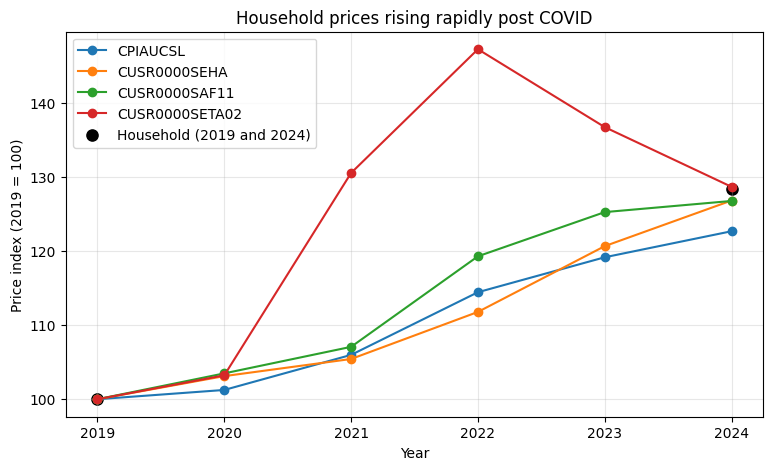

In [5]:
import matplotlib.pyplot as plt

rebased.plot(figsize=(9, 5), marker="o")

plt.scatter(
    [2019, 2024],
    [100, index*100],
    color="black",
    s=65,
    label="Household (2019 and 2024)"
  )

plt.title("Household prices rising rapidly post COVID")
plt.xlabel("Year")
plt.ylabel("Price index (2019 = 100)")
plt.xticks(range(2019, 2025))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
import pandas as pd
from pandas_datareader import data as web

series = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

fred_full = web.DataReader(series, "fred", "1947-01-01")

for name in series:
    data = fred_full[name].dropna()

    first = data.index.min()
    last = data.index.max()

    months = pd.date_range(first, last, freq="MS")
    missing = months.difference(data.index)

    print(name)
    print("First:", first.strftime("%Y-%m"))
    print("Last:", last.strftime("%Y-%m"))
    print("Frequency: Monthly")
    print("Missing months:", len(missing))
    print("Missing dates:", list(missing.strftime("%Y-%m")))
    print()

CPIAUCSL
First: 1947-01
Last: 2026-08
Frequency: Monthly
Missing months: 1
Missing dates: ['2025-10']

CUSR0000SEHA
First: 1981-01
Last: 2026-08
Frequency: Monthly
Missing months: 1
Missing dates: ['2025-10']

CUSR0000SAF11
First: 1952-01
Last: 2026-08
Frequency: Monthly
Missing months: 1
Missing dates: ['2025-10']

CUSR0000SETA02
First: 1953-01
Last: 2026-08
Frequency: Monthly
Missing months: 0
Missing dates: []



The data shows that CPIAUCSL, CUSR0000SEHA, and CUSR0000SAF11 are all missing one month. After investigating the month is October 2025 which we can safely assume to be as a result of the government shutdown at the time. I will simply exclude this month from further calculations for data as I find it better than to just invent an estimate

In [7]:
starts = {}
ends = {}

for name in series:
    starts[name] = fred_full[name].first_valid_index()
    ends[name] = fred_full[name].last_valid_index()

print("Start Dates:")
display(pd.DataFrame([starts]))

common_start = max(starts.values())
common_end = min(ends.values())

common_all = fred_full.loc[common_start:common_end, series]
common = common_all.dropna()

print("Common sample starts:", common_start.strftime("%Y-%m"))
print("Common sample ends:", common_end.strftime("%Y-%m"))
print("Calendar months:", len(common_all))
print("Months with complete data:", len(common))
print("Months discarded from CPIAUCSL:", (fred_full['CPIAUCSL'].dropna().index < common_start).sum())

Start Dates:


,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02
0,1947-01-01,1981-01-01,1952-01-01,1953-01-01


Common sample starts: 1981-01
Common sample ends: 2026-08
Calendar months: 548
Months with complete data: 547
Months discarded from CPIAUCSL: 408


In [8]:
own_change = (fred_full.loc["2024", series].mean() /
              fred_full.loc["2019", series].mean() - 1) * 100

common_change = (common.loc["2024", series].mean() /
                common.loc["2019", series].mean() - 1) * 100

comparison = pd.DataFrame({
    "Owb History (%)": own_change,
    "Common Sample (%)": common_change
})

comparison["Different (pp)"] = common_change - own_change

print(comparison.round(2))

household_change = (index - 1) * 100

print("Household - CPI, own history:",
      round(household_change - own_change["CPIAUCSL"], 2))
print("Household - CPI, common sample:",
      round(household_change - common_change["CPIAUCSL"], 2))

                Owb History (%)  Common Sample (%)  Different (pp)
CPIAUCSL                  22.70              22.70             0.0
CUSR0000SEHA              26.86              26.86             0.0
CUSR0000SAF11             26.80              26.80             0.0
CUSR0000SETA02            28.70              28.70             0.0
Household - CPI, own history: 5.7
Household - CPI, common sample: 5.7


The common sample stretches over 547 months of data. 408 months were removed from CPIAUCSL. Between the years of 2019 and 2024 CPi increased by 22.7% while my household estimates price increased by 28.7% with both methods having a difference of 0 percentage points as seen above. I would use the common sample for a cient as it makes sure that all series are covering the same period.

Restricting assumees that the shared period is enough on its own to compare while not restricting assumes different time periods will not alter the comparison

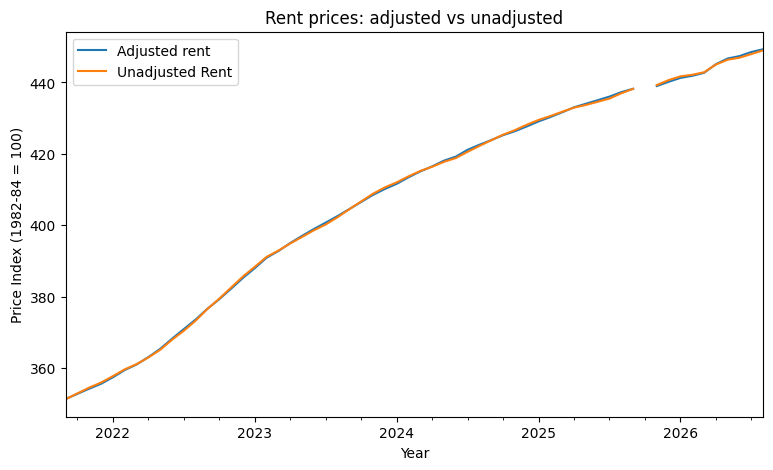

In [10]:
import matplotlib.pyplot as plt

rent_unadjusted = web.DataReader("CUUR0000SEHA", "fred", "2021-01-01")

rent_pair = pd.concat([
    fred_full["CUSR0000SEHA"],
    rent_unadjusted["CUUR0000SEHA"]
],axis=1)

rent_pair.columns = ["Adjusted rent", "Unadjusted Rent"]

rent_pair.tail(60).plot(figsize=(9, 5))

plt.title("Rent prices: adjusted vs unadjusted")
plt.xlabel("Year")
plt.ylabel("Price Index (1982-84 = 100)")
plt.legend()
plt.show()

The gap consists of the excluded months of October for which there is no data. If referrring to the gap between the two lines themselves then that is a result of seasonal adjustments. The series that I would use is the unadjusted rent as it better reflects what they actually pay. I would use the adjusted if I had to see overall price changes without seasonal changes.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Expects `household_basket` (list of dicts: Item, Price_2019, Price_2024, weight)
# to already exist in your session.

df = pd.DataFrame(household_basket)
base_weights = df["weight"].to_numpy(dtype=float)
price_relatives = (df["Price_2024"] / df["Price_2019"]).to_numpy(dtype=float)

if not np.isclose(base_weights.sum(), 1.0):
    raise ValueError(f"Base weights sum to {base_weights.sum():.4f}, expected 1.0")

weight_grid = np.linspace(0, 0.5, 101)
base_index = 100 * base_weights @ price_relatives

index_paths = {}
rows = []
for k, item in enumerate(df["Item"]):
    others_w = np.delete(base_weights, k)
    others_r = np.delete(price_relatives, k)

    # WHY RENORMALISE: a Laspeyres index only means something if weights sum to 1.
    # If category k is forced to weight w and the others are left alone, the
    # weights sum to something other than 1, so the index level shifts for a
    # reason unrelated to prices (the basket is "bigger" or "smaller").
    # Scaling every other weight by (1 - w) / (1 - base_w_k) keeps their relative
    # proportions and restores a sum of exactly 1, so the only thing that changes
    # is how much of the basket is category k.
    scale = (1 - weight_grid) / (1 - base_weights[k])
    index = 100 * (weight_grid * price_relatives[k] + scale * (others_w @ others_r))
    index_paths[item] = index

    # The index is linear in w, so the slope summarises sensitivity completely.
    slope = (index[-1] - index[0]) / (weight_grid[-1] - weight_grid[0])
    rows.append({
        "Item": item,
        "base_weight": base_weights[k],
        "price_relative": price_relatives[k],
        "points_per_0.10_weight": slope * 0.10,
        "range_over_sweep": index.max() - index.min(),
    })

sensitivity = (
    pd.DataFrame(rows)
    .assign(abs_effect=lambda d: d["points_per_0.10_weight"].abs())
    .sort_values("abs_effect", ascending=False)
    .reset_index(drop=True)
)
most_sensitive = sensitivity.loc[0, "Item"]
print(f"Base index: {base_index:.2f}")
print(sensitivity.drop(columns="abs_effect").round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
for item in sensitivity["Item"]:
    k = df.index[df["Item"] == item][0]
    is_top = item == most_sensitive
    effect = sensitivity.loc[sensitivity["Item"] == item, "points_per_0.10_weight"].iloc[0]
    line, = ax.plot(
        weight_grid, index_paths[item],
        linewidth=3 if is_top else 1.5,
        label=f"{item} ({effect:+.2f} pts per +0.10)",
    )
    ax.scatter(base_weights[k], base_index, color=line.get_color(), s=30, zorder=3)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Weight on swept category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weight (most sensitive: {most_sensitive})")
ax.legend(title="Category (sorted by sensitivity)", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("weight_sensitivity.png", dpi=150)
plt.show()

# WHAT HIGH SENSITIVITY TO ONE CATEGORY MEANS: the headline number is mostly a
# statement about that category's weight, not about the basket. If the weight
# estimate is off (survey error, a household whose spending differs from the
# base-year shares, substitution since 2019), the index moves materially.
# Steep slope = the category's price relative sits far from the rest of the
# basket AND a weight error there is costly. Report it as a risk to the result.

KeyError: 'Price_2024'

One thing Claude got wrong is that it referenced Price_2024 despite that not being a column.

The prompt was as follows: [Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

Ran a command, shared files
I wrote weight_sensitivity.py. It reads your household_basket, sweeps each weight from 0 to 0.5, rescales the others proportionally, and saves one chart with all six lines. It runs cleanly on placeholder data I made up to test it, so I can’t yet tell you which category dominates your result.

What the code does

Chart: Each line is the index as one category’s weight moves, with a dot at its actual base weight. The steepest line is drawn thickest, and the legend ranks categories by points of index per +0.10 of weight.
Table: A printed table gives the same ranking, plus each category’s price relative.
Weights check: It raises an error if your weights don’t sum to 1, rather than silently fixing them.
Comments: The two you asked for are in the script. They cover why the other weights must be renormalised and what high sensitivity to one category means.
Which category dominates
Run it on your data and read the top row of the table. Dominance is not simply the biggest weight. The index is linear in each weight, so the slope equals that category’s price relative minus the weighted average of the other five. The most sensitive category is the one whose inflation differs most from the rest of the basket. In my placeholder data, a heavy category (housing at 0.30) was the least sensitive because its price rise matched the rest of the basket, while a light one (energy at 0.10, +50%) dominated.

What to say to the client
Use the wording that matches your top row.

One category clearly ahead: “Our index is robust to errors in most weights, but it is sensitive to the weight on [category]. A shift of 0.10 in that weight moves the index by about X points, because its prices rose very differently from the rest of the basket. We recommend validating that weight against current spending data.”
Slopes all similar: “No single category drives the result, so the index is not fragile to any one weighting assumption.”
Either way, add one caveat. A Laspeyres index uses fixed 2019 weights, so if the client’s spending has shifted since 2019, the sensitive category is where that bias would show up first.

Dear Director,
  
As of recent, our estimated household expense has increased by 28.4% compared to 22.7% with the CPI. This suggests that this household experienced a increase 5.7% higher than the national average. It's worthy to note that as these household prices are estimates the client should be careful in drawing conclusions. Nonetheless, one can argue that CPI is understated per the findings. However, it cannot be ignored that this finding is targeted and tailored to one specefic worker. I recommend that the client decides to further analyze spending patterns before raising wages, yet be prepared as it is the likely conclusion.